In [4]:
# imports
import pandas as pd
import numpy as np
import librosa
from pathlib import Path
from scipy.fft import rfft
import umap 
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [5]:
df_PFS = pd.read_excel("descriptions.xlsx")
df_PFS.head()

,Fish sound,Filename,Begin time,End time,Low frequency (Hz),High frequency (Hz),Duration 90% (s),Centre frequency (Hz),Max power (dB) relative!,notes,category,extra notes,Unnamed: 12,Unnamed: 13
0,6.0,671633444.190702140024.wav,49.658,51.602,49.1,109.8,1.6,70.3,34.0,NaN,a,NaN,NaN,"show a spectrogram for a,b and c fish sounds"
1,9.0,1208221730.181207000246.wav,47.422,49.484,32.7,453.2,1.7,187.5,35.4,good,a,NaN,NaN,NaN
2,10.0,1208221730.181207000246.wav,66.964,67.798,14.0,355.1,0.6,46.9,43.5,NaN,a,NaN,NaN,NaN
3,11.0,1208221730.181207000246.wav,73.105,75.897,37.4,383.1,2.2,152.3,33.9,good,a,NaN,NaN,NaN
4,12.0,1208221730.181207002246.wav,8.168,9.749,39.6,287.4,1.2,128.9,35.6,good,a,NaN,NaN,NaN


In [6]:
def load_and_resample(path, target_sr=2048):
    y, sr = librosa.load(path, sr = target_sr)
    return y, target_sr
    
def frame_audio(y, frame_size=1024, hop_size=1024):
    frames = librosa.util.frame(y, frame_length=frame_size, hop_length=hop_size).T
    return frames
    
def frame_timestamps(num_frames, sr=2048, hop_size=1024):
    return np.arange(num_frames) * (hop_size / sr)

# def spectrogram_encode(y, sr, n_fft=1024, hop_length=256, win_length=256):
#     # Compute complex STFT
#     S = librosa.stft(
#         y,
#         n_fft=n_fft,
#         hop_length=hop_length,
#         win_length=win_length,
#         window='hann',
#         center=True,
#         pad_mode='constant'
#     )

#     # Convert to magnitude
#     S_mag = np.abs(S)
#     # X = np.log1p(S_mag) #log compression to stabilize noise
#     # Return frames × freq_bins (transpose)
#     return X.T

def spectrogram_encode(y, sr, n_fft=1024, hop_length=512):
    S = np.abs(librosa.stft(
        y,
        n_fft=n_fft,
        hop_length=hop_length,
        win_length=n_fft,
        window='hann',
        center=True,
        pad_mode='constant'
    ))
    return np.log1p(S).T  # log compression

def label_frames_from_df(timestamps, df, filename):
    # Filter rows for this file only
    df_file = df[df["Filename"] == filename]

    labels = []
    for t in timestamps:
        # Check if t falls inside ANY interval for this file
        is_call = np.any((df_file["Begin time"].values <= t) &
                         (df_file["End time"].values >= t))
        labels.append(1 if is_call else 0)

    return np.array(labels)

def category_frames_from_df(timestamps, df, filename):
    df_file = df[df["Filename"] == filename]

    labels = []
    for t in timestamps:
        # Find all intervals that contain this timestamp
        mask = (df_file["Begin time"].values <= t) & (df_file["End time"].values >= t)

        if np.any(mask):
            # Extract the category for the matching interval
            category = df_file["category"].values[mask][0]
            labels.append(category)
        else:
            labels.append(0)

    return np.array(labels)

def running_median_background(X, window=400):
    X_bg = np.zeros_like(X)
    for i in range(X.shape[0]):
        start = max(0, i - window // 2)
        end = min(X.shape[0], i + window // 2)
        X_bg[i] = np.median(X[start:end], axis=0)
    return X_bg


def process_multiple_files_df(df = df_PFS, sr=2048, option = 1):
    all_features = []
    all_labels = []
    all_file_ids = []

    # unique filenames from the dataframe
    file_paths = df_PFS[df["Filename"].notna()]["Filename"].unique()

    for fname in file_paths:
        path = Path(fname)  # same directory, so just the name

        # Step 1: load + resample
        y, _ = load_and_resample(str(path), target_sr=sr)

        # Step 2: frame
        # frames = frame_audio(y)
        # timestamps = frame_timestamps(len(frames), sr=sr)
        X = spectrogram_encode(y, sr)
        timestamps = frame_timestamps(X.shape[0], sr=sr)

        # Step 4: label using DataFrame (match on filename only)
        if option == 1: 
            y_labels = label_frames_from_df(timestamps, df, fname) 
        else: 
            y_labels = category_frames_from_df(timestamps, df, fname)

        all_features.append(X)
        all_labels.append(y_labels)
        all_file_ids.extend([fname] * len(y_labels))

    X_all = np.vstack(all_features)
    y_all = np.concatenate(all_labels)

    return X_all, y_all, all_file_ids



In [8]:
import noisereduce as nr

In [9]:
#load one for demo
sr = 1024
file_paths = df_PFS[df_PFS["Filename"].notna()]["Filename"].unique()
fname = file_paths[2]
path = Path(fname)  # same directory, so just the name

# Step 1: load + resample
y, _ = load_and_resample(str(path), target_sr=sr)

# Step 2: frame
# frames = frame_audio(y)
# timestamps = frame_timestamps(len(frames), sr=sr)
y_reduced = nr.reduce_noise(y=y, sr=sr, time_mask_smooth_ms = 320, prop_decrease = 0.20)
X = spectrogram_encode(y_reduced, sr, hop_length = 128, n_fft = 256) #50% overlap, can play with it

#throw out first 30 frames to avoid startup noise
X = X[30:,:]

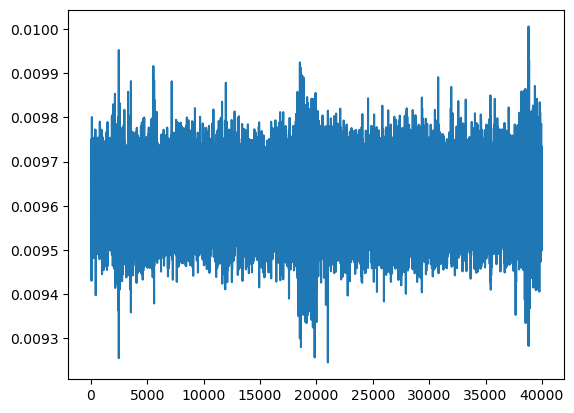

In [275]:
plt.plot(y[20000:60000])

In [276]:
print(fname)

1208221730.181207162246.wav


## Spectrogram a in paper: 

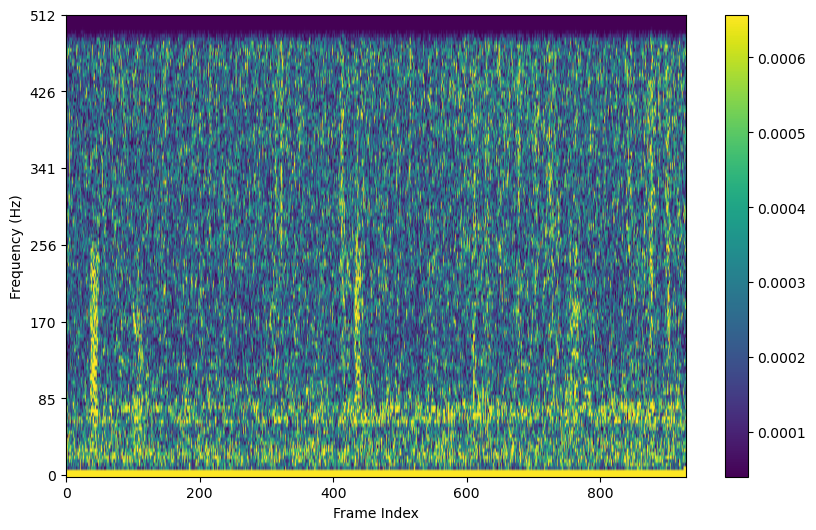

In [10]:
ylabels = np.linspace(0, sr/2, X.shape[1])
vmin = np.percentile(X, 5)
vmax = np.percentile(X, 95)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(
    X.T,
    aspect='auto',
    vmin=vmin,
    vmax=vmax,
    cmap='viridis'
)

ax.invert_yaxis()
ax.set_yticks(np.linspace(0, X.shape[1], 7))
ax.set_yticklabels(np.linspace(0, sr/2, 7).astype(int))
ax.set_ylabel("Frequency (Hz)")
ax.set_xlabel("Frame Index")
plt.colorbar(im, ax=ax)
plt.show()

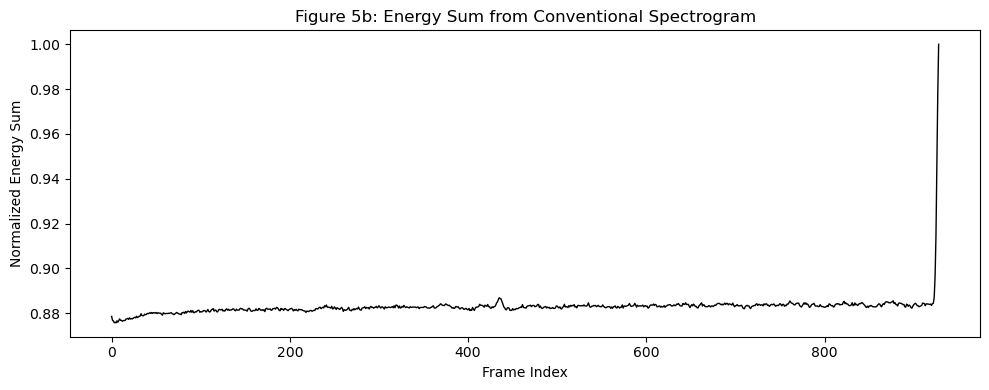

In [11]:
#energy vs time
energy = np.sum(X**2, axis=1)

# Optional: normalize for nicer plotting
energy_norm = energy / (np.max(energy) + 1e-12)

plt.figure(figsize=(10, 4))
plt.plot(energy_norm, color='black', linewidth=1)
plt.xlabel("Frame Index")
plt.ylabel("Normalized Energy Sum")
plt.title("Figure 5b: Energy Sum from Conventional Spectrogram")
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Average Magnitude')

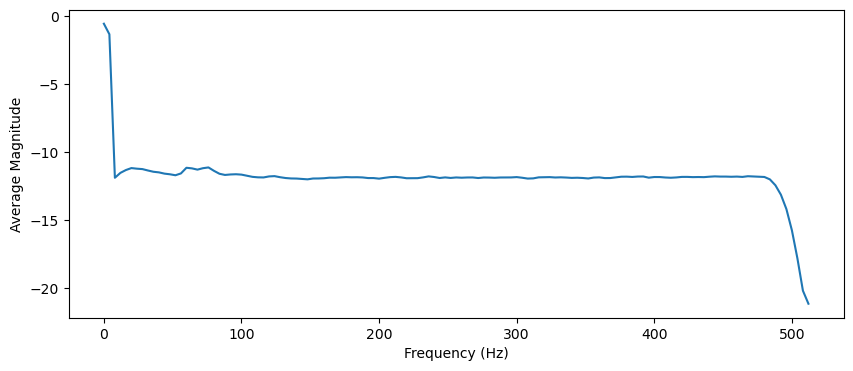

In [12]:
#exclude high energy frames and average spectrum
high_energy_threshold = np.percentile(energy, 90)
low_energy_frames = energy < high_energy_threshold


average_spectrum = np.mean(X[low_energy_frames], axis=0)
plt.figure(figsize=(10, 4))
plt.plot(ylabels, np.log2(average_spectrum))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Average Magnitude")

## Spectrogram 2 From Paper

In [13]:
import scipy

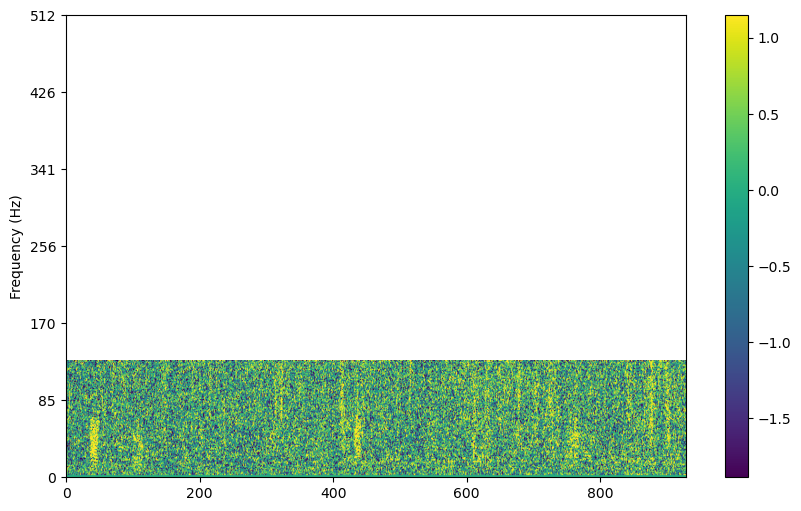

In [14]:
# #apply spectral whitening based on low energy frames
X_whitened = X / (np.median(X[low_energy_frames], axis=0) + 1e-10)  # add small value to avoid division by zero

log_whitened = np.log2(X_whitened + 1e-12)

# Compute contrast limits
vmin = np.percentile(log_whitened, 5)
vmax = np.percentile(log_whitened, 95)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(
    log_whitened.T,
    aspect='auto',
    vmin=vmin,
    vmax=vmax,
    cmap='viridis'
)

ax.invert_yaxis()
ax.set_yticks(np.linspace(0, 512, 7))
plt.colorbar(im, ax=ax)
ax.set_yticklabels(np.linspace(0, sr/2, 7).astype(int))
ax.set_ylabel("Frequency (Hz)")
plt.show()


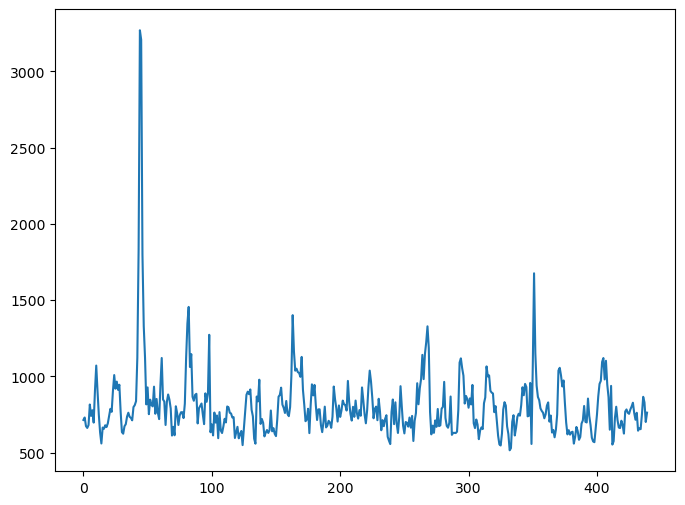

In [241]:
#energy vs time
energy = np.sum(X_whitened**2, axis=1)
plt.figure(figsize=(8, 6))
plt.plot(energy[:-10])
plt.show()

In [242]:
X_whitened_normalized = X_whitened / (np.max(X_whitened) + 1e-10)  # normalize to [0, 1]


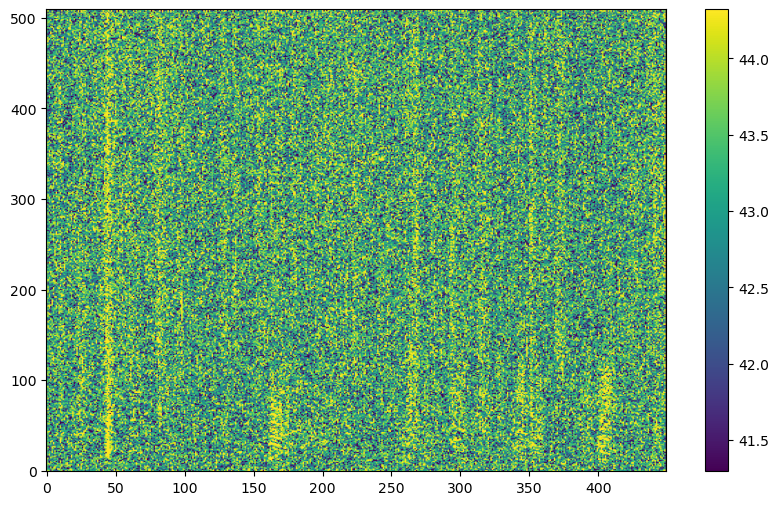

Text(0, 0.5, 'Cumulative Energy')

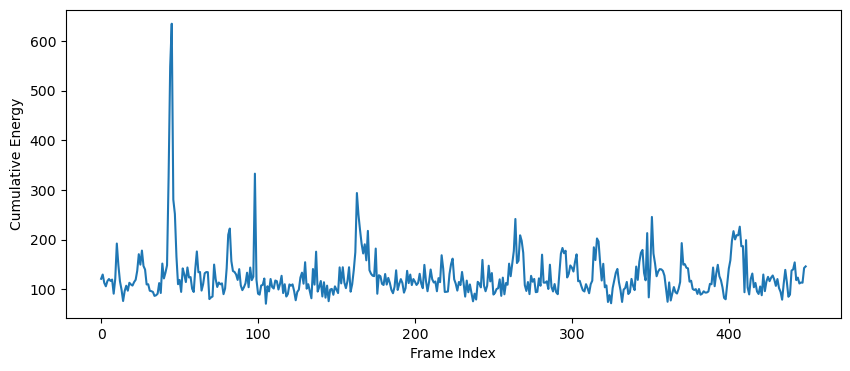

In [243]:
# Note: higher alpha --> more definition, but can amplify noise
# def power_law_transform(X_white, bg, alpha=1.3):
#     # bg is the same background spectrum used for whitening
#     bg_alpha = bg ** alpha
#     X_pl = X_white / (bg_alpha + 1e-12)
#     return X_pl

def power_law_transform(X, window = 20, alpha=1.0):
    #create running average of the spectrum
    X_avg = np.zeros_like(X)
    for i in range(X.shape[0]): #use wraparound or padding for edge effects
        start = max(0, i - window // 2)
        end = min(X.shape[0], i + window // 2 + 1)
    X_avg[i] = np.median(X[start:end], axis=0)
    #apply power law transform
    X_avg = np.maximum(X_avg, np.percentile(X_avg, 5))
    X_power_law = X / (X_avg + 1e-10) ** alpha  # add small value to avoid division by zero
    return X_power_law

X_pl = power_law_transform(X_whitened, alpha=1.3)
log_pl = np.log2(X_pl + 1e-12)

plt.figure(figsize=(10,6))
plt.imshow(
    log_pl.T,
    aspect='auto',
    vmin=np.percentile(log_pl, 5),
    vmax=np.percentile(log_pl, 95),
    cmap='viridis'
)
plt.gca().invert_yaxis()
plt.colorbar()
ax.invert_yaxis()
ax.set_yticks(np.linspace(0, 512, 7))

plt.show()

#create running sum of energy across all frequencies
energy_running_sum = (np.sum(X_whitened_normalized_power_law**2, axis=1))/(X_whitened_normalized_power_law.shape[1])  # average energy per frame
plt.figure(figsize=(10, 4))
plt.plot(energy_running_sum)
plt.xlabel("Frame Index")
plt.ylabel("Cumulative Energy")



Text(0, 0.5, 'Cumulative Energy')

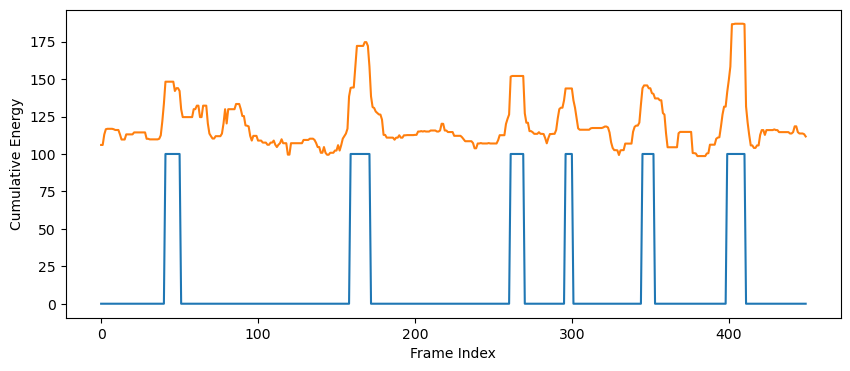

In [255]:
from scipy import signal

energy_running_sum = (np.sum(X_whitened_normalized_power_law**2, axis=1))/(X_whitened_normalized_power_law.shape[1])  # average energy per frame
new_energy = scipy.signal.medfilt(energy_running_sum, 15)

trigger = new_energy > 140
plt.figure(figsize=(10, 4))
plt.plot(trigger *100)
plt.plot(new_energy)
plt.xlabel("Frame Index")
plt.ylabel("Cumulative Energy")


* run on other files, see if effective